# Poner precio a un incumplimiento inferior o superior

Nivel 1. Requisitos previos: derivadas elementales y arreglos Python. Tiempo de lectura: 20 minutos.

**Pregunta:** ¿Cuánto incumple una decisión escalar su intervalo cuando el lado superior tiene mayor precio que el inferior?


## Objetivos

Un límite blando es una decisión económica del modelo de optimización. No es una solicitud para que el solver ignore una fila problemática después de fallar. Mantendremos el intervalo y la curvatura unitaria, cambiaremos solo precios declarados y observaremos los minimizadores. El ejemplo es adimensional: sus valores no representan directamente confort físico ni capacidad de un actuador.

Al terminar podrá distinguir objetivo deseado, límite, incumplimiento y penalización. El objetivo deseado expresa la preferencia sin restricciones. El intervalo establece una región operacional deseada. El incumplimiento mide la distancia a esa región. Su precio determina si el optimizador compra esa distancia. Una decisión elástica óptima puede quedar fuera del intervalo y, aun así, satisfacer exactamente el modelo matemático.


## Preparación

Utilice un entorno separado de Python 3.12. El motor nativo es una distribución separada. Instale el entorno exacto fuera del cuaderno:

```bash
pip install "softqp==0.1.0"
pip install "numpy==2.5.4"
pip install "scipy==1.18.1"
pip install "matplotlib==3.11.2"
pip install "osqp==1.1.3"
pip install "daqp==0.10.3"
pip install "elastiqp==0.2.0"
```

La única celda de preparación localiza el repositorio, importa los métodos e imprime versiones numéricas. No se instala software dentro del kernel.


In [1]:
# Localizar entradas una vez deja las celdas científicas dedicadas a optimización.
from pathlib import Path
import sys
import json
import importlib.metadata
import numpy as np
import matplotlib.pyplot as plt
from softqp.solvers import solve
candidates = [Path.cwd(), *Path.cwd().parents]
root = next(p for p in candidates if (p / "VERSION").is_file() and (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
from pipeline.softqp_cases import scalar, mpc
for distribution in ("softqp", "numpy", "scipy", "matplotlib", "osqp", "daqp", "elastiqp"):
    print(distribution, importlib.metadata.version(distribution))
accurate = dict(eps_abs=1e-9, eps_rel=1e-9, adaptive_rho_interval=25)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
case_spec = json.loads((root / "docs/contracts/examples/softqp-case-spec.json").read_text(encoding="utf-8"))
case_record = json.loads((root / "data/derived/softqp/C01.json").read_text(encoding="utf-8"))


softqp 0.1.0
numpy 2.5.4
scipy 1.18.1
matplotlib 3.11.2
osqp 1.1.3
daqp 0.10.3
elastiqp 0.2.0


## Datos

El generador propio `scalar` entrega P=1, A=1 e intervalo [-1,1]. El coeficiente lineal del objetivo es el negativo del valor deseado. C01 usa -3 y C02 usa +3. C03 mantiene el objetivo positivo y cambia los precios superiores lineal/cuadrático de 0.3/2 a 1.2/4. La fuente es `data-pipeline/pipeline/softqp_cases.py`; no hay mediciones externas ni ajuste oculto.

Propietario de las entradas: Felipe Santibáñez-Leal. El generador elaborado y los archivos escalares de especificación y resultado se distribuyen con la licencia MIT del producto; véase el [inventario público de fuentes y licencias](https://github.com/fsantibanezleal/CAOS_SoftQP). `docs/contracts/examples/softqp-case-spec.json` enseña la forma dispersa de entrada y `data/derived/softqp/C01.json` enseña el resultado. Contienen entradas matemáticas sintéticas y salidas calculadas, no observaciones operacionales de terceros.


El diagrama de entrada separa los objetivos libres de los resultados del optimizador. El intervalo horizontal representa la región deseada y los tres marcadores son entradas del generador, antes de aplicar los precios. Su separación no corresponde a mediciones de una planta. Además leemos una sola vez la especificación escalar serializada y el registro de resultado, para relacionar el ejemplo con el formato de intercambio del producto.


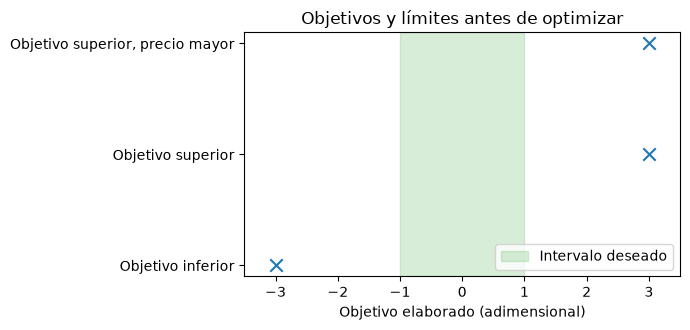

In [2]:
# Mostrar las entradas antes de resolver separa datos y política.
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.axvspan(-1, 1, alpha=0.18, color="C2", label="Intervalo deseado")
ax.scatter([-3, 3, 3], [0, 1, 2], marker="x", s=80, color="C0")
ax.set_yticks([0, 1, 2], ['Objetivo inferior', 'Objetivo superior', 'Objetivo superior, precio mayor'])
ax.set(xlabel='Objetivo elaborado (adimensional)', title='Objetivos y límites antes de optimizar', xlim=(-3.5, 3.5))
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()


Los objetivos libres quedan fuera del intervalo sombreado: hay un conflicto inferior y dos objetivos superiores iguales. Los dos puntos superiores se separan verticalmente por el nombre de su política para que su coincidencia horizontal no sugiera entradas distintas. Límites y objetivos comparten una unidad de decisión adimensional. La figura posterior mostrará cómo los precios transforman estas entradas en mínimos; ninguna de las dos figuras representa una observación física.


## Método

Escribimos el objetivo original como $F(x)=x^2/2-tx+\phi(x)$, con penalización $a_l(l-x)_++a_u(x-u)_++b_l(l-x)_+^2/2+b_u(x-u)_+^2/2$. La parte positiva impide cobrar por el lado que no se incumple. Con coeficientes no negativos, cada término es convexo; la cuadrática unitaria hace que este objetivo escalar sea estrictamente convexo y tenga minimizador único.

Primero resolvemos el objetivo negativo con la ruta nativa que admite asimetría. En este primer caso los coeficientes son simétricos. Examine el incumplimiento inferior sin deducirlo del signo del objetivo: se omitió la constante dependiente del valor deseado, de modo que un objetivo negativo es completamente válido.


### El umbral y el precio cumplen funciones distintas

La convención en coordenadas originales del paquete se especializa aquí en una variable. El símbolo $t$ representa el objetivo libre, $l=-1$ y $u=1$ delimitan el intervalo deseado, $a_l,a_u$ son precios lineales y $b_l,b_u$ son precios cuadráticos. Los cuatro coeficientes son no negativos. Un incumplimiento es una distancia y no la holgura correctiva con signo utilizada por algunas interfaces. La función es

$$F(x)=\frac12x^2-tx+a_l(l-x)_++a_u(x-u)_++\frac{b_l}{2}(l-x)_+^2+\frac{b_u}{2}(x-u)_+^2,\qquad (v)_+=\max(v,0).$$

Esta convención proviene del generador del producto y de la formulación por lado del informe técnico. La [formulación de OSQP](https://osqp.org/docs/solver/) fija la convención de media forma cuadrática. La constante omitida $t^2/2$ convertiría los primeros términos en error de seguimiento al cuadrado; agregarla no mueve el mínimo. Por eso un objetivo numérico negativo no significa que el problema sea inválido ni que exista un costo físico negativo.

Cuando el objetivo libre está sobre el límite superior, los términos inferiores desaparecen. La derivada fuera del intervalo es $x-t+a_u+b_u(x-u)$. Su raíz sólo sirve en esa rama cuando permanece sobre $u$. Al combinar la raíz con el punto angular del borde obtenemos

$$x^*=u+\frac{(t-u-a_u)_+}{1+b_u},\qquad t\geq u.$$

El caso inferior reflejado usa $x^*=l-(l-t-a_l)_+/(1+b_l)$ cuando $t\leq l$. Si el objetivo está dentro del intervalo, ningún precio actúa y la decisión puede coincidir con él. Estas expresiones permiten un cálculo manual para este caso unidimensional; no implementan un solucionador de problemas acoplados. Con $t=3$, el precio simétrico permite una distancia $(3-1-0.3)/(1+2)=0.566667$. La política superior más cara permite $(3-1-1.2)/(1+4)=0.160000$. Las tres llamadas nativas posteriores calculan las decisiones correspondientes sin utilizar esa fórmula como algoritmo.

La ecuación distingue el efecto lineal del cuadrático. El precio lineal produce un umbral: si $a_u$ alcanza $t-u$, este mínimo particular llega al borde aunque $b_u$ sea finito. El precio cuadrático reduce la distancia mediante el denominador, pero por sí solo no elimina una preferencia exterior con un coeficiente finito. Una fila dura retira todos los puntos exteriores del conjunto admisible. Llamar duro a un peso cuadrático grande confundiría una aproximación útil con una restricción matemática.

La derivada también aclara por qué la política más cara no representa un algoritmo más preciso. Ambas políticas se resuelven con la misma tolerancia numérica, pero minimizan funciones distintas. La precisión mide cuán cerca está el resultado del mínimo de su función declarada. La política determina cuál de esas funciones se eligió. En la lección de comparación mantendremos la función fija al contrastar implementaciones. Antes de elegir un precio para datos físicos hay que especificar la consecuencia que se quiere valorar; una tolerancia de resolución nunca reemplaza esa decisión.


In [3]:
# Un precio finito permite un compromiso inferior en vez de imponer un recorte duro.
lower_problem = scalar(-3.0)
lower = solve(lower_problem, "asymmetric", **accurate)
print(f"Decisión inferior: {lower['x'][0]:.6f}")
print(f"Incumplimiento inferior: {lower['metrics']['lower_violation'][0]:.6f}")


Decisión inferior: -1.566667
Incumplimiento inferior: 0.566667


Reflejar el valor deseado y conservar precios simétricos debería reflejar el óptimo. Es una propiedad del objetivo declarado, no una garantía de toda implementación numérica. Resolver el caso positivo por separado permite examinar la salida efectiva. El precio cuadrático finito reduce continuamente el incumplimiento; en general no convierte el intervalo deseado en una restricción dura.


In [4]:
# Reflejar el valor deseado sin cambiar precios por lado.
upper_problem = scalar(3.0)
upper = solve(upper_problem, "asymmetric", **accurate)
print(f"Decisión superior simétrica: {upper['x'][0]:.6f}")


Decisión superior simétrica: 1.566667


Ahora cobramos más por el lado superior y mantenemos el inferior. Para un punto sobre u, derivar entrega x=(t-a_u+b_u u)/(1+b_u) siempre que la expresión permanezca sobre u; de otro modo debe considerarse el quiebre. El cálculo explica por qué cambiar un precio modifica la decisión preferida. No compara algoritmos: las tres llamadas utilizan el mismo método nativo.


In [5]:
# El caso asimétrico propio cambia costos, no límites ni curvatura.
priced_problem = scalar(3.0, asymmetric=True)
priced = solve(priced_problem, "asymmetric", **accurate)
print(f"Decisión superior de mayor precio: {priced['x'][0]:.6f}")
print(f"Incumplimiento superior de mayor precio: {priced['metrics']['upper_violation'][0]:.6f}")


Decisión superior de mayor precio: 1.160000
Incumplimiento superior de mayor precio: 0.160000


Compare los dos objetivos de valor deseado positivo sobre el mismo eje de decisión. Cada curva se recalcula con el evaluador original, no con el costo interno del solver. Las marcas verticales ubican los minimizadores devueltos. Las curvas completas revelan mejor el cambio de política que un número de iteraciones o llamar más preciso al resultado más cercano al intervalo.


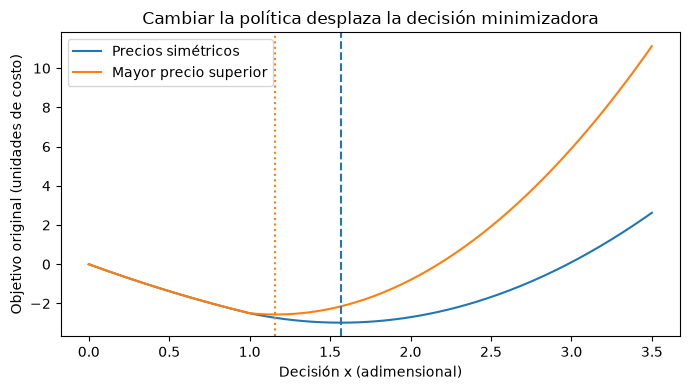

In [6]:
# Ambas curvas mantienen el mismo valor deseado para mostrar el efecto del precio.
grid = np.linspace(0.0, 3.5, 250)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(grid, [upper_problem.evaluate([x])["objective"] for x in grid], label="Precios simétricos")
ax.plot(grid, [priced_problem.evaluate([x])["objective"] for x in grid], label="Mayor precio superior")
ax.axvline(upper["x"][0], linestyle="--", color="C0")
ax.axvline(priced["x"][0], linestyle=":", color="C1")
ax.set(xlabel="Decisión x (adimensional)", ylabel="Objetivo original (unidades de costo)",
       title="Cambiar la política desplaza la decisión minimizadora")
ax.legend()
fig.tight_layout()
plt.show()


La curva superior de mayor pendiente alcanza su mínimo más cerca del límite deseado. Ambos minimizadores superan uno porque ninguna política hace dura la fila y los precios finitos permiten compensar el incumplimiento con la preferencia del objetivo. Las curvas comparten convención de costo, pero sus mínimos representan políticas diferentes y no clasifican precisión de solvers. Un ingeniero de control elegiría el precio relativo según las consecuencias antes de seleccionar un algoritmo numérico.


### De una fila a un problema intercambiable

La especificación leída utiliza matrices dispersas CSC. `shape` indica sus dimensiones, `data` contiene los coeficientes no nulos, `indices` contiene los índices de fila e `indptr` separa las columnas. Los vectores `q`, `lower` y `upper` pertenecen a los espacios originales de decisiones y filas. Un límite JSON `null` significa que ese lado no existe; convertirlo en cero inventaría una frontera. Las listas de `penalty` conservan por separado `lower_linear`, `upper_linear`, `lower_quadratic` y `upper_quadratic`. La máscara `soft` establece si la fila puede ceder. Cada lista debe tener tantas entradas como filas.

El resultado tiene otra finalidad. `case_id` identifica el caso elaborado, `schema_version` identifica la estructura del documento y `rows` conserva identificador, unidad física y política dura o blanda de cada fila. Cada elemento de `runs` mantiene el método y su estado junto a su salida. Una ejecución incompatible lleva una razón, no una decisión inventada. En un caso resuelto, las distancias inferiores y superiores conservan su correspondencia con las filas, mientras el evaluador reconstruye el objetivo original. Así el consumidor puede separar una nueva política matemática de una falla numérica.

Para otras entradas escalares, cambie el objetivo con `scalar(target, lower=..., upper=..., asymmetric=...)` y use la misma API `solve`. Si los datos describen un sistema físico diferente, construya primero la especificación dispersa con unidades significativas, en lugar de asignar un nombre industrial a este ejemplo normalizado. Las operaciones declaradas en `pipeline.pipeline.STAGES` son `validate`, `assemble`, `solve`, `evaluate` y `export`: admitir y decodificar la especificación, construir el caso, resolverlo, evaluar su costo e incumplimientos originales y exportar significado y procedencia. Este cálculo determinista no esconde entrenamiento ni un predictor aprendido. La distinción evita atribuir generalización estadística a tres optimizaciones escalares.


## Resultados

**Respuesta:** La decisión de objetivo negativo es -1.566667 y la decisión superior de mayor precio es 1.160000. Sus incumplimientos tienen magnitudes 0.566667 y 0.160000. La diferencia responde a precios asimétricos, no a cambiar la amplitud del intervalo. La decisión positiva simétrica refleja el resultado negativo.

La rama analítica explica estos valores calculados bajo curvatura unitaria. En un QP mayor, el acoplamiento entre variables impide tratar cada fila como problema escalar independiente: el solver resuelve ese acoplamiento y la operación proximal escalar maneja la penalización declarada del intervalo.


## Resumen

Antes de interpretar una solución elástica, identifique lado incumplido, unidad física, precio lineal y precio cuadrático. Un incumplimiento finito puede ser el óptimo deseado. Aumentar una penalización interviene la política; reducir una tolerancia interviene el cálculo numérico. Distinguir ambas operaciones será esencial en la próxima lección, donde los actuadores mantienen restricciones duras y las preferencias de estado pueden ceder.


## Referencias

- [Formulación del solver OSQP](https://osqp.org/docs/solver/).
- [Schwan, Lew y Plancher, proyecciones generalizadas de holgura](https://arxiv.org/abs/2610.35631).
- Entrada escalar propia y evaluador original del repositorio y su dependencia fija `softqp`.

- [SoftQP authored scalar data and exchange specifications](https://github.com/fsantibanezleal/CAOS_SoftQP).
- [SoftQP product technical report](https://doi.org/10.5281/zenodo.23851659).
